In [1]:
import re
import json
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

### Detect

In [2]:
# Mypy and pyright df
df = pd.read_csv('bigbenchcode_responses_df.csv')

In [3]:
df.columns

Index(['id', 'code', 'passed', 'result', 'metadata', 'model', 'cid',
       'error_type', 'execute', 'passed_mypy', 'result_mypy', 'time_mypy',
       'passed_pyright', 'result_pyright', 'time_pyright',
       'result_static_pyright_unjson', 'result_static_mypy_unjson',
       'static_union', 'static_union_str', 'pyright_str', 'mypy_str'],
      dtype='object')

In [4]:
model_names = ['claude-3-opus-20240229-0','gpt-3.5-0125-0','gpt-4-0613','ibm-granite']

In [5]:
def get_detected_stats(df, col_exp, imaginary=False, model_names=[]):
    for m in model_names:
        print(f"Model: {m}")
        df_m = df[df['model'] == m]
        if imaginary == 'syntax':
            df_m = df_m[df_m['error_type'].isin(['SyntaxError'])]
        elif imaginary:
            df_m = df_m[df_m['error_type'].isin(['ImportError','ModuleNotFoundError','AttributeError','TypeError'])]
        print(confusion_matrix(df_m['execute'], df_m[col_exp]))
        print(classification_report(df_m['execute'], df_m[col_exp]))

In [57]:
get_detected_stats(df, 'passed_pyright', False, model_names)
#get_detected_stats(df, 'passed_pyright', True, model_names)
#get_detected_stats(df, 'passed_mypy', False, model_names)
#get_detected_stats(df, 'passed_mypy', True, model_names)

In [6]:
get_detected_stats(df, 'passed_mypy', True, model_names)

Model: claude-3-opus-20240229-0
[[ 2 70]
 [ 0  0]]
              precision    recall  f1-score   support

           0       1.00      0.03      0.05        72
           1       0.00      0.00      0.00         0

    accuracy                           0.03        72
   macro avg       0.50      0.01      0.03        72
weighted avg       1.00      0.03      0.05        72

Model: gpt-3.5-0125-0
[[ 3 88]
 [ 0  0]]
              precision    recall  f1-score   support

           0       1.00      0.03      0.06        91
           1       0.00      0.00      0.00         0

    accuracy                           0.03        91
   macro avg       0.50      0.02      0.03        91
weighted avg       1.00      0.03      0.06        91

Model: gpt-4-0613
[[ 7 78]
 [ 0  0]]
              precision    recall  f1-score   support

           0       1.00      0.08      0.15        85
           1       0.00      0.00      0.00         0

    accuracy                           0.08        85

/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python

In [10]:
# LLM files
def get_response(response):
    if response[0].startswith('Yes'):
        return 1
    elif response[0].startswith('No'):
        return 0
        
bigcode_llm = pd.read_json('results/llm/o3-mini-bug-bigcodebench-0-answers.jsonl',lines=True)
bigcode_llm['result'] = bigcode_llm['response'].apply(get_response)

In [11]:
merge_llm_responses = df.merge(bigcode_llm[['id','model','result']], on=['id','model'], suffixes=('','_llm'))

In [12]:
get_detected_stats(merge_llm_responses, 'result_llm', 'syntax', model_names)

Model: claude-3-opus-20240229-0
[[0 1]
 [0 0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       1.0
           1       0.00      0.00      0.00       0.0

    accuracy                           0.00       1.0
   macro avg       0.00      0.00      0.00       1.0
weighted avg       0.00      0.00      0.00       1.0

Model: gpt-3.5-0125-0
[[0 1]
 [0 0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       1.0
           1       0.00      0.00      0.00       0.0

    accuracy                           0.00       1.0
   macro avg       0.00      0.00      0.00       1.0
weighted avg       0.00      0.00      0.00       1.0

Model: gpt-4-0613
[[0 2]
 [0 0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       2.0
           1       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro av

/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anac

In [13]:
# Grammar files
# Change format for detect script
all_responses = []
folder_path = 'results/grammar/bigcodebench/'
files_responses = ['claude-3-opus-20240229-0_grammar_validation.jsonl', 'gpt-3.5-turbo-0125-0_grammar_validation.jsonl', 'gpt-4-0613-0_grammar_validation.jsonl', 'granite-code-latest-0_grammar_validation.jsonl']
for model, file in zip(model_names, files_responses):
    file_path = f'{folder_path}{file}'
    responses = [json.loads(l) for l in open(file_path, "r")]
    for response in responses:
        response["model"] = model
        all_responses.append(response)

In [14]:
grammar_df = pd.DataFrame(all_responses)
grammar_df['result_grammar'] = grammar_df['passed'].apply(lambda x : 1 if x == 'pass' else 0)
merged_grammar = df.merge(grammar_df, on=['model','cid'])

In [15]:
get_detected_stats(merged_grammar, 'result_grammar', 'syntax', model_names)

Model: claude-3-opus-20240229-0
[[0 1]
 [0 0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       1.0
           1       0.00      0.00      0.00       0.0

    accuracy                           0.00       1.0
   macro avg       0.00      0.00      0.00       1.0
weighted avg       0.00      0.00      0.00       1.0

Model: gpt-3.5-0125-0
[[1]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1

    accuracy                           1.00         1
   macro avg       1.00      1.00      1.00         1
weighted avg       1.00      1.00      1.00         1

Model: gpt-4-0613
[[1 1]
 [0 0]]
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.00      0.00      0.00         0

    accuracy                           0.50         2
   macro avg       0.50      0.25      0.33         2
weighted avg       1

/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anac

### Repair

In [ ]:
def get_repair(exp, repair_model, dataset, df_check):
    df_test_all = pd.DataFrame()
    model_names = ["ibm-granite"]
    for model in model_names:
        #print(df_check.columns)
        df_check['model'] = df_check['model'].apply(lambda x : 'ibm-granite' if x == 'granite-code-latest-no-grammar-0' else x)
        df_check['model'] = df_check['model'].apply(lambda x : 'ibm-granite' if x == 'granite-code-latest' else x)
        df_m = df_check[df_check['model']== 'ibm-granite']
        print(df_m.columns)
        df_m = df_m[['id','passed','error_type','execute','model','result']]
        file_path = f'../../Data/bigcodebench/repair/{repair_model}/{exp}/{model}-answers.jsonl'
        file_path = f'o3-mini/repair/{repair_model}/{repair_model}-repair-{exp}-0-{dataset}-answers.jsonl'
        if dataset == 'ds':
            file_path = file_path.replace('-answers.jsonl','-errors.jsonl')
        df_model_repair = get_repair_data(file_path, model)
        if dataset == 'ds':
            df_model_repair['id'] = df_model_repair['completion_id']
        df_model_repair = df_model_repair[['id','passed','error_type', 'execute','model','result']]
        #df_m = df_m[df_m['execute'] == 1]
        # Drop ids in df_m that appear in df_model_repair
        if dataset == 'odex':
            # Count cumulative occurrences in each df
            df_m["_rank"] = df_m.groupby("id").cumcount() + 1
            df_m["_rank"] =  df_m["_rank"].astype(str)
            df_model_repair["_rank"] = df_model_repair.groupby("id").cumcount() + 1
            df_model_repair["_rank"] =  df_model_repair["_rank"].astype(str)
            # Create a composite key
            df_m["_key"] = df_m["id"].astype(str) + "_" + df_m["_rank"].astype(str)
            df_model_repair["_key"] = df_model_repair["id"].astype(str) + "_" + df_model_repair["_rank"].astype(str)
            # Filter
            df_m = df_m[~df_m["_key"].isin(df_model_repair["_key"])]
            # Cleanup
            #df_m = df_m.drop(columns=["_rank", "_key"])
        else:
            df_m = df_m[~df_m["id"].isin(df_model_repair["id"])]
        print(len(df_m))
        # Concat dfs'
        df_test = pd.concat([df_m, df_model_repair])
        print(len(df_model_repair))
        print(len(df_test))
        df_test_all = pd.concat([df_test_all, df_test])
    df_experiment = get_results_exp(df_test_all, experiment=exp, sample=1000)
    #df_experiment['repair_model'] = repair_model 
    return df_experiment#, df_m, df_model_repair

In [12]:
import re

def get_error_type(row):
    passed = row['passed']
    text = row['result']
    if 'timeout' in passed:
        return 'timeout'
    if "http://lib.stat.cmu.edu/datasets/boston" in text:
        return 'ImportError'
    # Regex to match and extract 'AssertionError'
    match = re.search(r"\b([\w\.]+(?:[Ee]rror|[Ee]xceptions?|[Ss]chema))(?=:)", text)
    if match:
        extracted_error = match.group(1)
        return extracted_error
    else:
        decompose_message = text.strip().split('\n')
        if len(decompose_message) > 0:
            last_text = decompose_message[-1]
            if 'No module' in last_text:
                return 'ModuleNotFoundError'
            if 'cannot import' in last_text:
                return 'ImportError'
            if 'demand_for_clean_air' in text:
                return text
            if 'name' in text and 'not defined' in text:
                return 'NameError'
            return last_text
        else:
            return text

def get_execute(row):
    if row['passed'] == 'pass' or row['error_type'] == 'AssertionError':
        return 1
    return 0

def get_repair_data(exp_file, model_name):
    repair_exp = pd.read_json(exp_file,lines=True)
    #repair_exp['cid'] = repair_exp['id'].apply(lambda x : x[x.find('/')+1:]).astype(int)
    repair_exp['error_type'] = repair_exp.apply(get_error_type, axis=1)
    repair_exp['execute'] = repair_exp.apply(get_execute, axis=1)
    repair_exp['model'] = model_name
    return repair_exp

In [13]:
def calculate_execute_rate(df, sample):
    df_m = df[df['execute']==1]
    rs = df_m.groupby('model')['id'].count().reset_index()
    rs['id'] = ((rs['id']/sample)* 100).round(1)
    rs.rename(columns={'id':'ER'}, inplace=True)
    return rs

def calculate_passk(df, sample):
    df_m = df[df['passed']=='pass']
    rs = df_m.groupby('model')['id'].count().reset_index()
    rs['id'] = ((rs['id']/sample)* 100).round(1)
    rs.rename(columns={'id':'PASSK'}, inplace=True)
    return rs

def calcualte_if_count(df, sample):
    df_m = df[df['error_type'].isin(['ImportError','ModuleNotFoundError','AttributeError','TypeError'])]
    rs = df_m.groupby('model')['id'].count().reset_index()
    df_errors = df[df['execute']==0].groupby('model')['id'].count().reset_index()
    r_ifs = rs.merge(df_errors, on=['model'], suffixes=('_ifs','_errors'))
    r_ifs['id'] = r_ifs['id_ifs']/r_ifs['id_errors']
    r_ifs['id'] = (r_ifs['id']* 100).round(1)
    r_ifs.rename(columns={'id':'IFs'}, inplace=True)
    return r_ifs[['model','IFs']]

def get_results_exp(df, sample=1140, experiment=''):
    er_df = calculate_execute_rate(df, sample)
    pas_df = calculate_passk(df, sample)
    if_df = calcualte_if_count(df, sample)
    results_df = er_df.merge(pas_df, on=['model'])
    results_df = results_df.merge(if_df, on=['model'])
    results_df['row'] = experiment
    return results_df

In [130]:
get_results_exp(df, experiment='No repair')

,model,ER,PASSK,IFs,row
0,claude-3-opus-20240229-0,79.0,45.5,30.1,No repair
1,gpt-3.5-0125-0,77.6,39.3,35.7,No repair
2,gpt-4-0613,79.6,46.0,36.6,No repair
3,ibm-granite,61.0,20.6,40.0,No repair


In [138]:
def get_repair(exp, repair_model):
    df_test_all = pd.DataFrame()
    model_names = ["claude-3-opus-20240229-0", "gpt-3.5-0125-0", "gpt-4-0613", "ibm-granite"]
    for model in model_names:
        df_m = df[df['model']== model]
        df_m = df_m[['id','passed','error_type', 'execute','model']]
        file_path = f'Data/bigcodebench/repair/{repair_model}/{exp}/{model}-answers.jsonl'
        df_model_repair = get_repair_data(file_path, model)
        df_model_repair = df_model_repair[['id','passed','error_type', 'execute','model']]
        # Drop ids in df_m that appear in df_model_repair
        df_m = df_m[~df_m["id"].isin(df_model_repair["id"])]
        # Concat dfs'
        df_test = pd.concat([df_m,df_model_repair])
        df_test_all = pd.concat([df_test_all, df_test])
    df_experiment = get_results_exp(df_test_all, experiment=exp)
    #df_experiment['repair_model'] = repair_model 
    return df_experiment

In [132]:
exp = ['pyright','mypy', 'general']
df_results = pd.DataFrame()
for e in exp:
    df_results = pd.concat([df_results, get_repair(e, 'o3-mini')])
df_results

,model,ER,PASSK,IFs,row
0,claude-3-opus-20240229-0,80.0,45.9,28.9,pyright
1,gpt-3.5-0125-0,78.3,39.4,36.4,pyright
2,gpt-4-0613,80.4,46.1,34.5,pyright
3,ibm-granite,66.7,23.2,38.2,pyright
0,claude-3-opus-20240229-0,79.0,45.5,30.5,mypy
1,gpt-3.5-0125-0,77.9,39.4,35.7,mypy
2,gpt-4-0613,80.0,46.1,36.4,mypy
3,ibm-granite,62.2,21.1,39.0,mypy
0,claude-3-opus-20240229-0,82.6,47.3,29.8,general
1,gpt-3.5-0125-0,82.1,41.3,34.3,general


In [139]:
exp = ['pyright','mypy', 'general']
df_results = pd.DataFrame()
for e in exp:
    df_results = pd.concat([df_results, get_repair(e, 'ibm-granite')])
df_results

,model,ER,PASSK,IFs,row
0,claude-3-opus-20240229-0,79.0,45.4,28.0,pyright
1,gpt-3.5-0125-0,77.0,38.9,34.7,pyright
2,gpt-4-0613,79.3,45.9,35.2,pyright
3,ibm-granite,62.0,21.3,36.3,pyright
0,claude-3-opus-20240229-0,78.9,45.4,30.8,mypy
1,gpt-3.5-0125-0,77.7,39.2,35.8,mypy
2,gpt-4-0613,79.5,45.8,36.3,mypy
3,ibm-granite,61.1,20.6,39.3,mypy
0,claude-3-opus-20240229-0,79.3,45.6,18.2,general
1,gpt-3.5-0125-0,78.3,39.4,22.7,general


### Constrained-decoding

In [4]:
def clean_code(code):
    pattern = r"python\s*(.*?)"
    match = re.search(pattern, code, re.DOTALL)
    if match:
        code_block = match.group(1).strip()
        return code_block
    else:
        return ''
def clean_code(predicted):
    if '```python' in predicted :
        pred_list =  [element.strip() for element in re.findall(r'```python(.*?)```', predicted, re.DOTALL)]
        pred_list = '\n'.join(pred_list)
    else:
        pred_list = predicted
    return pred_list

In [25]:
constrained_file = 'Data/bigcodebench/results/granite-code-latest-0-constrained-answers.jsonl'
output_file = 'Data/bigcodebench/results/granite-code-1-constrained-answers.jsonl'
# Read IBM response
constrained_pre = []
with open(constrained_file, "r") as f:
    for i, line in enumerate(f, 1):
        try:
            obj = json.loads(line)
            constrained_pre.append(obj)
        except json.JSONDecodeError as e:
            print(f"Line {i} ERROR:", e, "->", repr(line[:100]))

# Clean code
with open(output_file, 'a') as f:
    for c in constrained_pre:
        if c["solution"] != ["timed out"]:
            r = {"task_id": c["task_id"], "solution": clean_code(c["solution"])}
            f.write(json.dumps(r) + '\n')

In [8]:
def get_error_type(row):
    passed = row['passed']
    text = row['result']
    if 'timeout' in passed:
        return 'timeout'
    if "http://lib.stat.cmu.edu/datasets/boston" in text:
        return 'ImportError'
    # Regex to match and extract 'AssertionError'
    match = re.search(r"\b([\w\.]+(?:[Ee]rror|[Ee]xceptions?|[Ss]chema))(?=:)", text)
    if match:
        extracted_error = match.group(1)
        return extracted_error
    else:
        decompose_message = text.strip().split('\n')
        if len(decompose_message) > 0:
            last_text = decompose_message[-1]
            if 'No module' in last_text:
                return 'ModuleNotFoundError'
            if 'cannot import' in last_text:
                return 'ImportError'
            if 'demand_for_clean_air' in text:
                return text
            if 'name' in text and 'not defined' in text:
                return 'NameError'
            return last_text
        else:
            return text

def get_execute(row):
    if row['passed'] == 'pass' or row['error_type'] == 'AssertionError':
        return 1
    return 0

In [43]:
responses = [json.loads(l) for l in open('Data/bigcodebench/results/ibm-granite-grammar-answers-validation.json', "r")]
responses_df = pd.DataFrame(responses)
responses_df['cid'] = responses_df['id'].apply(lambda x : x[x.find('/')+1:]).astype(int)
responses_df['error_type'] = responses_df.apply(get_error_type, axis=1)
responses_df['execute'] = responses_df.apply(get_execute, axis=1)
responses_df['model'] = 'ibm-granite-grammar'

In [44]:
get_results_exp(responses_df, experiment='No repair')

,model,ER,PASSK,IFs,row
0,ibm-granite-grammar,54.2,12.7,46.6,No repair


In [45]:
responses_df = responses_df[responses_df['error_type'].isin(['ImportError','ModuleNotFoundError','AttributeError','TypeError'])]

In [47]:
responses_df.groupby('error_type')['cid'].count().sort_values(ascending=False)[:15]

error_type
TypeError              121
AttributeError         120
ModuleNotFoundError      2
Name: cid, dtype: int64

In [18]:
responses = [json.loads(l) for l in open('Data/bigcodebench/results/ibm-granite-no-grammar-answers-validation.json', "r")]
responses_df = pd.DataFrame(responses)
responses_df['cid'] = responses_df['id'].apply(lambda x : x[x.find('/')+1:]).astype(int)
responses_df['error_type'] = responses_df.apply(get_error_type, axis=1)
responses_df['execute'] = responses_df.apply(get_execute, axis=1)
responses_df['model'] = 'ibm-granite-no-grammar'

In [19]:
get_results_exp(responses_df, experiment='No repair')

,model,ER,PASSK,IFs,row
0,ibm-granite-no-grammar,58.1,16.0,44.1,No repair


In [16]:
responses_df = responses_df[responses_df['error_type'].isin(['ImportError','ModuleNotFoundError','AttributeError','TypeError'])]
responses_df.groupby('error_type')['cid'].count().sort_values(ascending=False)[:15]

error_type
TypeError              118
AttributeError          91
ModuleNotFoundError      2
Name: cid, dtype: int64

In [ ]:
# Unconstrained code with my IBM model

In [22]:
constrained_file = 'Data/bigcodebench/results/granite-code:latest-0-no-constrained-answers.jsonl'
output_file = 'Data/bigcodebench/results/granite-code-1-no-constrained-answers.jsonl'
# Read IBM response
unconstrained_pre = []
with open(constrained_file, "r") as f:
    for i, line in enumerate(f, 1):
        try:
            obj = json.loads(line)
            unconstrained_pre.append(obj)
        except json.JSONDecodeError as e:
            print(f"Line {i} ERROR:", e, "->", repr(line[:100]))

# Clean code
with open(output_file, 'a') as f:
    for c in unconstrained_pre:
        if c["solution"] != ["timed out"]:
            r = {"task_id": c["task_id"], "solution": clean_code(c["solution"])}
            f.write(json.dumps(r) + '\n')

In [23]:
constrained_file = 'Data/bigcodebench/results/granite-code-latest-0-constrained-answers.jsonl'
output_file = 'Data/bigcodebench/results/granite-code-1-constrained-answers.jsonl'
# Read IBM response
constrained_pre = []
with open(constrained_file, "r") as f:
    for i, line in enumerate(f, 1):
        try:
            obj = json.loads(line)
            constrained_pre.append(obj)
        except json.JSONDecodeError as e:
            print(f"Line {i} ERROR:", e, "->", repr(line[:100]))

In [24]:
unconstrained_pre_duration = [c["duration"] for c in unconstrained_pre if c["solution"] != ["timed out"]]
constrained_pre_duration = [c["duration"] for c in constrained_pre if c["solution"] != ["timed out"]]

In [36]:
import numpy as np
np.mean(unconstrained_pre_duration)

22.33509860791658

In [37]:
np.mean(constrained_pre_duration)

34.76321181454162

In [29]:
time_detection = pd.concat([pd.DataFrame({'method':'unconstrained','duration': unconstrained_pre_duration}),
pd.DataFrame({'method':'constrained','duration': constrained_pre_duration})])

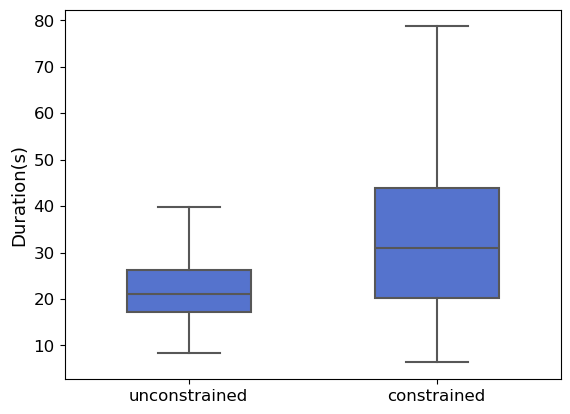

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(data=time_detection, x='method', y='duration',showfliers=False, width=0.5, color="royalblue")
#plt.suptitle("Detection")
plt.ylabel("Duration(s)", fontsize=13)
plt.xlabel("", fontsize=13)
plt.grid(False)
plt.savefig("constrained_time.png")
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)

# Show plot
plt.show()